<a href="https://colab.research.google.com/github/PARODBE/Clase/blob/main/Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#SCALING PANDAS

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler, PowerTransformer

Xin, _ = fetch_california_housing(return_X_y=True, as_frame=True)
X = Xin["Population"].sample(frac=0.5).values.reshape(-1, 1)
X = Xin["Population"].sample(frac=0.5)

In [ ]:
X

,Population
17160,980.0
15238,380.0
1207,864.0
443,288.0
3644,2397.0
...,...
16484,301.0
11834,845.0
16557,830.0
6782,632.0


In [ ]:
Xin["Population"].sample(frac=0.5).values.reshape(-1, 1)

array([[ 655.],
       [1816.],
       [ 828.],
       ...,
       [1097.],
       [1181.],
       [1071.]])

Text(0.5, 1.0, 'Base')

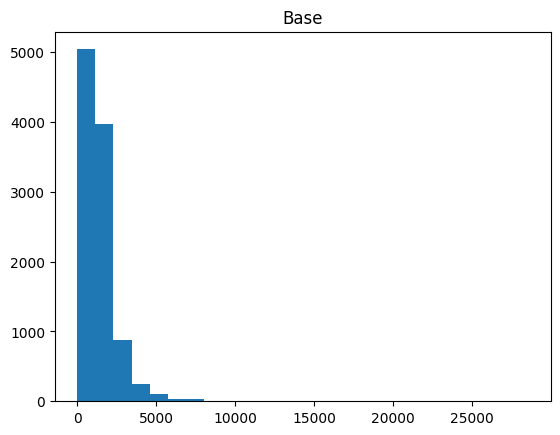

In [ ]:
X, _ = fetch_california_housing(return_X_y=True, as_frame=True)
X = X.sample(frac=0.5).loc[:, "Population"]
plt.figure()
plt.hist(X, bins=25)
plt.title("Base")

In [ ]:
X.max()

28566.0

transform


Text(0.5, 1.0, 'Standard Scaler')

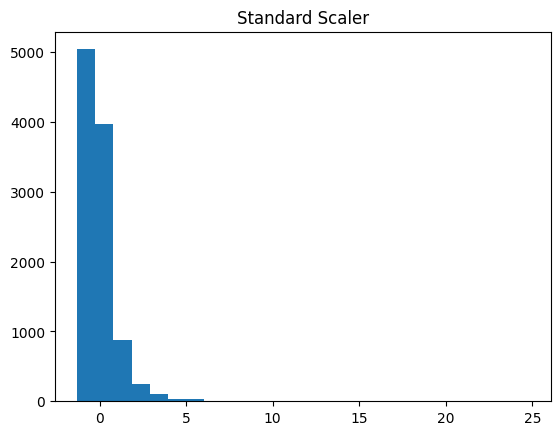

In [ ]:
# TRANSFORMACION X a NDARRAY
X = X.values.reshape(-1,1)

# STANDARIZATION
scaler = StandardScaler()
scaler.fit(X)
X_std = scaler.transform(X)
print("transform")
plt.figure()
plt.hist(X_std, bins=25)
plt.title("Standard Scaler")

Text(0.5, 1.0, 'MinMax Scaler')

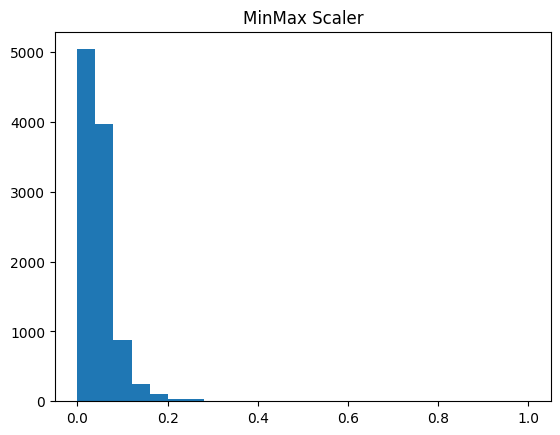

In [ ]:
# MINMAX
scaler = MinMaxScaler()
scaler.fit(X)
X_mm = scaler.transform(X)
plt.figure()
plt.hist(X_mm, bins=25)
plt.title("MinMax Scaler")

Text(0.5, 1.0, 'Robust Scaler')

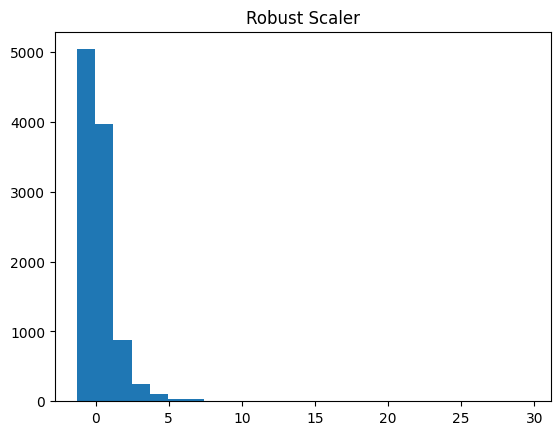

In [ ]:
# ROBUST
scaler = RobustScaler()
scaler.fit(X)
X_robust = scaler.transform(X)
plt.figure()
plt.hist(X_robust, bins=25)
plt.title("Robust Scaler")

Text(0.5, 1.0, 'MaxAbs Scaler')

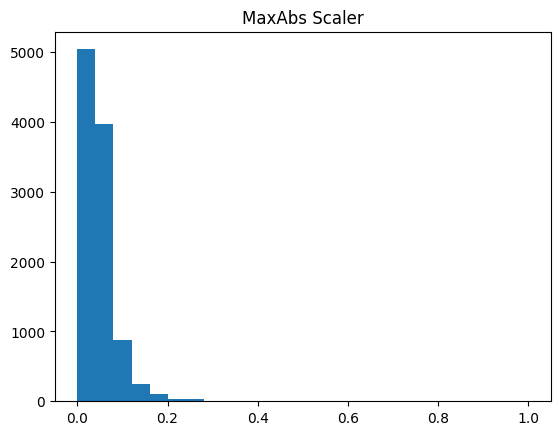

In [ ]:
# MAXABS
scaler = MaxAbsScaler()
scaler.fit(X)
X_abs = scaler.transform(X)
plt.figure()
plt.hist(X_abs, bins=25)
plt.title("MaxAbs Scaler")

Text(0.5, 1.0, 'Box-Cox')

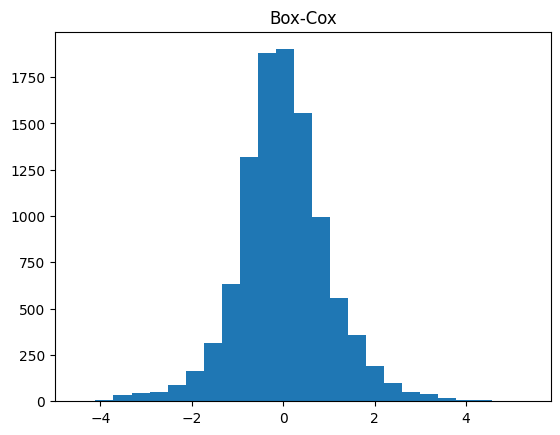

In [ ]:
# BOXCOX
boxcox = PowerTransformer(method="box-cox", standardize=True)
boxcox.fit(X)
X_bc = boxcox.transform(X)
plt.figure()
plt.hist(X_bc, bins=25)
plt.title("Box-Cox")

Text(0.5, 1.0, 'Yeo-Johnson')

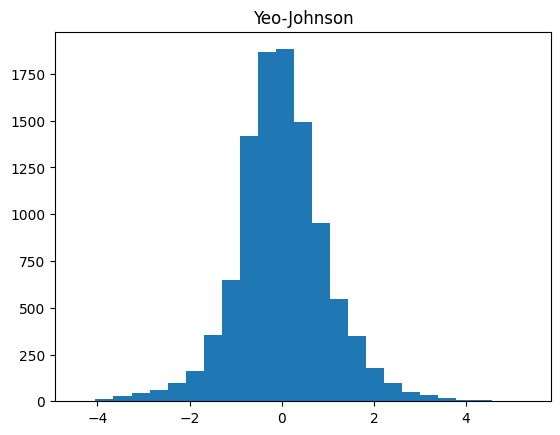

In [ ]:
# YEO-JHONSON
yeo = PowerTransformer(method="yeo-johnson", standardize=True)
yeo.fit(X)
X_yj = yeo.transform(X)
plt.figure()
plt.hist(X_yj, bins=25)
plt.title("Yeo-Johnson")

<Axes: ylabel='Count'>

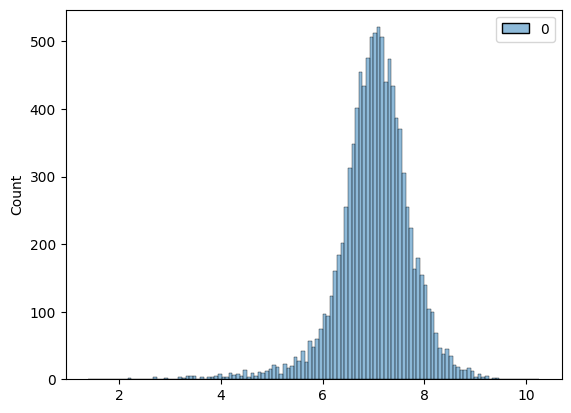

In [ ]:
import numpy as np
import seaborn as sns

sns.histplot(np.log1p(X))


# BINNING

In [ ]:
import pandas as pd
X = Xin["Population"]

X_bin, bins = pd.cut(X, bins=5, retbins=True)

In [ ]:
bins

array([-3.26790e+01,  7.13880e+03,  1.42746e+04,  2.14104e+04,
        2.85462e+04,  3.56820e+04])

In [ ]:
bins[1]-bins[0]

np.float64(7171.479)

In [ ]:
X_bin

,Population
0,"(-32.679, 7138.8]"
1,"(-32.679, 7138.8]"
2,"(-32.679, 7138.8]"
3,"(-32.679, 7138.8]"
4,"(-32.679, 7138.8]"
...,...
20635,"(-32.679, 7138.8]"
20636,"(-32.679, 7138.8]"
20637,"(-32.679, 7138.8]"
20638,"(-32.679, 7138.8]"


In [ ]:
X_bin.value_counts()

,count
Population,
"(-32.679, 7138.8]",20527
"(7138.8, 14274.6]",107
"(14274.6, 21410.4]",4
"(28546.2, 35682.0]",2
"(21410.4, 28546.2]",0


In [ ]:

X_bin, bins = pd.cut(X, bins=[-0.01, 3000, 40000], retbins=True)

In [ ]:
X_bin.value_counts()

,count
Population,
"(-0.01, 3000.0]",19283
"(3000.0, 40000.0]",1357


In [ ]:
X_bin, bins = pd.qcut(X, q=5, retbins=True)

In [ ]:
bins

array([3.0000e+00, 7.1000e+02, 1.0070e+03, 1.3484e+03, 1.9080e+03,
       3.5682e+04])

In [ ]:
X_bin.to_frame().groupby("Population").size()

/tmp/ipython-input-4191701037.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  X_bin.to_frame().groupby("Population").size()


,0
Population,
"(2.999, 710.0]",4133
"(710.0, 1007.0]",4133
"(1007.0, 1348.4]",4118
"(1348.4, 1908.0]",4135
"(1908.0, 35682.0]",4121


#ENCODING

In [ ]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop="first")
X = [['Male', 1], ['Female', 3], ['Female', 2]]
enc.fit(X)
out = enc.transform(X)

In [ ]:
pd.DataFrame(X)

,0,1
0,Male,1
1,Female,3
2,Female,2


In [ ]:
pd.DataFrame(out)

,0,1,2
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,1.0,0.0


In [ ]:
out.toarray()

array([[0., 1., 1., 0., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 1., 0.]])

In [ ]:
print(enc.categories_)
enc.get_feature_names_out()

[array(['Female', 'Male'], dtype=object), array([1, 2, 3], dtype=object)]


array(['x0_Male', 'x1_2', 'x1_3'], dtype=object)

In [ ]:
print(enc.inverse_transform([[0, 1, 1], [0, 0, 0]]))

[['Female' 2]
 ['Female' 1]]


Opción simple: Dummy

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/employees_pandas/dept_emp.csv", index_col=0)
df

,emp_no,dept_no,from_date,to_date
0,10001,d005,1986-06-26,NaN
1,10002,d007,1996-08-03,NaN
2,10003,d004,1995-12-03,NaN
3,10004,d004,1986-12-01,NaN
4,10005,d003,1989-09-12,NaN
...,...,...,...,...
1098,10996,d007,1990-02-07,NaN
1099,10997,d004,2000-01-04,NaN
1100,10998,d007,1996-08-07,NaN
1101,10999,d005,1996-03-05,1997-04-19


In [ ]:
dummies = pd.get_dummies(df.dept_no, drop_first=True)
dummies.astype(int)

,d002,d003,d004,d005,d006,d007,d008,d009
0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,1,0,0
2,0,0,1,0,0,0,0,0
3,0,0,1,0,0,0,0,0
4,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...
1098,0,0,0,0,0,1,0,0
1099,0,0,1,0,0,0,0,0
1100,0,0,0,0,0,1,0,0
1101,0,0,0,1,0,0,0,0


In [ ]:
!pip install category-encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 2.7 MB/s eta 0:00:00


In [ ]:
from category_encoders.binary import BinaryEncoder

enc = BinaryEncoder()

enc.fit(df.dept_no.values.reshape(-1,1))
output_depts = enc.transform(df.dept_no.values.reshape(-1,1))

In [ ]:
pd.concat([df, output_depts], axis=1)

,emp_no,dept_no,from_date,to_date,0_0,0_1,0_2,0_3
0,10001,d005,1986-06-26,NaN,0,0,0,1
1,10002,d007,1996-08-03,NaN,0,0,1,0
2,10003,d004,1995-12-03,NaN,0,0,1,1
3,10004,d004,1986-12-01,NaN,0,0,1,1
4,10005,d003,1989-09-12,NaN,0,1,0,0
...,...,...,...,...,...,...,...,...
1098,10996,d007,1990-02-07,NaN,0,0,1,0
1099,10997,d004,2000-01-04,NaN,0,0,1,1
1100,10998,d007,1996-08-07,NaN,0,0,1,0
1101,10999,d005,1996-03-05,1997-04-19,0,0,0,1


In [ ]:
from sklearn.preprocessing import LabelEncoder


enc = LabelEncoder()
enc.fit(df.dept_no.values.reshape(-1,1))
output_depts = enc.transform(df.dept_no.values.reshape(-1,1))

/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_label.py:93: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


In [ ]:
df["ordinal_encoder"] = output_depts
df

,emp_no,dept_no,from_date,to_date,ordinal_encoder
0,10001,d005,1986-06-26,NaN,4
1,10002,d007,1996-08-03,NaN,6
2,10003,d004,1995-12-03,NaN,3
3,10004,d004,1986-12-01,NaN,3
4,10005,d003,1989-09-12,NaN,2
...,...,...,...,...,...
1098,10996,d007,1990-02-07,NaN,6
1099,10997,d004,2000-01-04,NaN,3
1100,10998,d007,1996-08-07,NaN,6
1101,10999,d005,1996-03-05,1997-04-19,4
